# tcxp quickstart

tcxp is the Typed ConteXt Protocol. In tcxp, the address is the state.
Rules, decisions, traces, simulations and SQL cards all read or write addresses.

This notebook walks through the library in ten short steps.
Everything runs offline. The last step (real models) is optional.

## 1. Install

The cell below checks whether tcxp is already importable.
If it is not, it installs it with pip.

In [1]:
try:
    import tcxp  # already installed (or on PYTHONPATH)
except ImportError:
    %pip install -q tcxp

## 2. Import

Check the version. The library describes itself with an address, too.

In [2]:
import tcxp
print(tcxp.__version__, tcxp.__uri__)

0.1.0 !tcxp:/lib/tcxp?dialect=tcxp-sql/0.1&version=0.1.0


## 3. Addresses

An `Address` is an immutable value. Editing it returns a new one.
An empty value (`tax_year=`) means the slot is known to be missing: it is Dark.

In [3]:
from tcxp import Address

addr = Address.parse("!tcxp:/reason?tax_year=&task=section_41_qre")
print("parsed:   ", addr)
print("tax_year: ", repr(addr.get("tax_year")))

addr2 = addr.with_(tax_year=2024)
print("edited:   ", addr2)
print("original: ", addr, "(unchanged)")

parsed:    !tcxp:/reason?task=section_41_qre&tax_year=
tax_year:  ''
edited:    !tcxp:/reason?task=section_41_qre&tax_year=2024
original:  !tcxp:/reason?task=section_41_qre&tax_year= (unchanged)


The canonical form is the core guarantee. The same state always gives the same string.
Key order in the input does not matter.
`to_uri()` writes a virtual pointer so standard URI tools accept it.

In [4]:
same = Address.parse("!tcxp:/reason?task=section_41_qre&tax_year=2024")
print("canonical: ", str(same))
print("equal:     ", same == addr2)
print("to_uri():  ", addr2.to_uri())
print("round trip:", Address.parse(addr2.to_uri()) == addr2)

canonical:  !tcxp:/reason?task=section_41_qre&tax_year=2024
equal:      True
to_uri():   tcxp:/reason?task=section_41_qre&tax_year=2024
round trip: True


Every address is a table of keys and values. `tcxp.convert` writes that table in other formats.

In [5]:
for fmt in ("json", "cpp", "java"):
    print(f"--- {fmt} ---")
    print(tcxp.convert(addr2, fmt))
    print()

--- json ---
{
  "address": "!tcxp:/reason?task=section_41_qre&tax_year=2024",
  "form": "virtual",
  "authority": "",
  "path": "reason",
  "params": {
    "task": "section_41_qre",
    "tax_year": "2024"
  }
}

--- cpp ---
// !tcxp:/reason?task=section_41_qre&tax_year=2024
#include <map>
#include <string>
#include <vector>

const std::map<std::string, std::vector<std::string>> state = {
    {"task", {"section_41_qre"}},
    {"tax_year", {"2024"}},
};

--- java ---
// !tcxp:/reason?task=section_41_qre&tax_year=2024
import java.util.List;
import java.util.Map;

Map<String, List<String>> state = Map.ofEntries(
    Map.entry("task", List.of("section_41_qre")),
    Map.entry("tax_year", List.of("2024"))
);



## 4. Spikes and facets

A `Spike` is one observation. Its `data` is what was seen.
It has three context facets: `meaning`, `structure` and `environment`.
A facet is Lit when it holds an address, and Dark when it is empty.

Here are two readings of the same text, `"05/04/2026"`.
One says the structure is month-first. The other says day-first.

In [6]:
from tcxp import Spike, dark_count, spikes_in

us = Spike("date", "05/04/2026", structure=("!tcxp:/schema/date/mm-dd-yyyy",))
eu = Spike("date", "05/04/2026", structure=("!tcxp:/schema/date/dd-mm-yyyy",))
us_again = Spike("date", "05/04/2026", structure=("!tcxp:/schema/date/mm-dd-yyyy",))

print("same data?           ", us.data == eu.data)
print("structure us vs eu:  ", us.compare(eu, "structure"))
print("structure us vs us:  ", us.compare(us_again, "structure"))
print("meaning   us vs eu:  ", us.compare(eu, "meaning"))
print("Lit facets: ", us.lit, " Dark facets:", us.dark)

same data?            True
structure us vs eu:   NO MATCH
structure us vs us:   MATCH
meaning   us vs eu:   DARK
Lit facets:  ('structure',)  Dark facets: ('meaning', 'environment')


Comparison is string equality on canonical addresses. A MATCH is never false.
DARK means at least one side has nothing to compare.

A spike can also live inside an address, as four keys.
`dark_count` counts the empty facets in a whole address.

In [7]:
state = Address.build("reason", us.to_params())
print(state)
print("spikes:    ", spikes_in(state))
print("dark_count:", dark_count(state))

!tcxp:/reason?date=05/04/2026&date.environment=&date.meaning=&date.structure=!tcxp:/schema/date/mm-dd-yyyy
spikes:     [Spike(key='date', data='05/04/2026', meaning=(), structure=('!tcxp:/schema/date/mm-dd-yyyy',), environment=(), sensor='', target='', start=-1, end=-1, time='')]
dark_count: 2


## 5. The Section 41 Observatron

A context object holds sensors, rules and state.
An Observatron is a context object mounted on an input (here, a query box).

The demo answers a tax question about Section 41 qualified research expenses (QREs).
A manager's rule says: don't give the answer until the tax year is confirmed.

In [8]:
from tcxp.demo import section41, MANAGER_RULE
from tcxp.pretty import show_address, show_card, show_verdict

ctx, obs, db, card = section41()
print("Manager's rule:", MANAGER_RULE)
print("As an address: ", ctx.reason[0].address())

Manager's rule: Don't give the answer until the tax year is confirmed
As an address:  !tcxp:/rule/answer-requires-tax-year?by=manager&require=tax_year&text=Don%27t%20give%20the%20answer%20until%20the%20tax%20year%20is%20confirmed&verdict=ASK&when=answer


Feed it a question. The sensors fire spikes. The Governor returns a verdict.
The question never names a tax year, so the verdict is ASK.

In [9]:
o = obs.feed("What should I deduct for Section 41 US-based QREs?")
print(show_verdict(o.verdict, color=False))
print()
for s in o.spikes:
    print(f"spike  {s.key:8} {s.data!r:14} lit={s.lit}")

 ASK  ASK: tax_year before 'answer'

spike  task     'deduct'       lit=('meaning',)
spike  task     'Section 41'   lit=('meaning',)
spike  task     'QREs'         lit=('meaning',)
spike  country  'US-based'     lit=('meaning',)


The state, key by key. Lit values have an address. Dark values are empty.
The SQL card shows which slots it still needs.

Output is shown without color here. Leave out `color=False` to get color in Jupyter or Colab.

In [10]:
print(show_address(ctx.address, ctx.schema.essential, color=False))
print()
print(show_card(card, ctx.address.to_dict(), color=False))

!tcxp:/reason/section-41?country=US&country.meaning=!tcxp:/geo/iso-3166/US&query=What%20should%20I%20deduct%20for%20Section%2041%20US-based%20QREs%3F&task=section_41_qre&task.meaning=!tcxp:/tax/us/irc-41&tax_year=&tax_year.environment=&tax_year.meaning=!tcxp:/tax/us/tax-year&tax_year.structure=
key                   value                                               status
────────────────────  ──────────────────────────────────────────────────  ──────
country               US
country.meaning       !tcxp:/geo/iso-3166/US                              LIT
query                 What should I deduct for Section 41 US-based QREs?
task                  section_41_qre
task.meaning          !tcxp:/tax/us/irc-41                                LIT
tax_year               (empty)                                            DARK
tax_year.environment   (empty)                                            DARK
tax_year.meaning      !tcxp:/tax/us/tax-year                              LIT
tax_year.struct

A person supplies the tax year. `confirm` records it as a learnable trace row.
Now the Governor says ACT, and the SQL card can run against the payroll table.

In [11]:
ctx.confirm("tax_year", 2024, by="you")
v = ctx.decide()
print(show_verdict(v, color=False))
print()
print(show_card(card, ctx.address.to_dict(), color=False))

result = card.run(db, ctx.address.to_dict())
print()
print(result.columns[0], "=", result.scalar())
print("card address:", card.address(ctx.address.to_dict()))

 ACT  ACT: everything 'answer' needs is known

US wages in the tax year  (ready to run)
  SELECT SUM(wages) FROM payroll WHERE country = 'US' AND pay_date BETWEEN '2024-01-01' AND '2024-12-31'

SUM(wages) = 99000
card address: !tcxp:/sql/card/us-wages?country=US&dialect=tcxp-sql/0.1&end_date=2024-12-31&start_date=2024-01-01


Every change landed in the trace. Each row is hash-chained to the one before it.
`verify` returns a list of problems. An empty list means the history is intact.

In [12]:
from tcxp.pretty import show_trace

print(show_trace(ctx.trace, color=False))
print()
print("verify:", ctx.trace.verify(ctx.registry))

#   time                      op       key              value                                    cause
──  ────────────────────────  ───────  ───────────────  ───────────────────────────────────────  ─────────────────  ─────────
0   2026-10-03T22:32:10.650Z  set                       (empty)                                  init
1   2026-10-03T22:32:10.650Z  trigger  rule             !tcxp:/rule/answer-requires-tax-year?b…  rule:add
2   2026-10-03T22:32:10.659Z  set      query            What should I deduct for Section 41 US…  input:query
3   2026-10-03T22:32:10.659Z  trigger  task             deduct                                   sensor:task
4   2026-10-03T22:32:10.659Z  set      task             section_41_qre                           sensor:task
5   2026-10-03T22:32:10.659Z  set      task.meaning     !tcxp:/tax/us/irc-41                     sensor:task
6   2026-10-03T22:32:10.659Z  trigger  task             Section 41                               sensor:task
7   2026-10-03T22:

## 6. The context roll

The context roll is a piano roll for addresses.
Each column is a step in the trace. `▼ NOW` marks the current step.
A cell lights up when its value changes.

We build one `Step` per trace row.

In [13]:
from tcxp.roll import Roll, Step

steps = []
for row in ctx.trace.rows:
    change = f"{row.op} {row.key}" + (f" = {row.value}" if row.value else "") + f" ({row.cause})"
    steps.append(Step(row.index, row.time, change, ctx.resolve(row.address)))

roll = Roll(steps)
print(len(steps), "steps")

14 steps


Two frames: the step where the Governor asks, and the step where you confirm the year.

In [14]:
ask_step = next(i for i, s in enumerate(steps) if s.change.startswith("decide"))
confirm_step = next(i for i, s in enumerate(steps) if "person:you" in s.change)

for now in (ask_step, confirm_step):
    print(roll.render(now, color=False))
    print()

tcxp context roll · step 11/13 · 2026-10-03T22:32:10.660Z · decide answer = ASK (governor)
                               -3          -2          -1        ▼ NOW         +1          +2
                                                               ──────────
!tcxp:/reason/section-41                   ●           ●                       ●
  country                      ·           US          US          US          US          US
  country.meaning                                     ↗US         ↗US         ↗US         ↗US
  query                    What shou…  What shou…  What shou…  What shou…  What shou…  What shou…
  task                     section_4…  section_4…  section_4…  section_4…  section_4…  section_4…
  task.meaning              ↗irc-41     ↗irc-41     ↗irc-41     ↗irc-41     ↗irc-41     ↗irc-41
  tax_year                     ·           ·           ·           ·          2024        2024
  tax_year.environment         ·           ·           ·           ·           ·     

In a notebook you can animate it. Each frame replaces the last one.

In [15]:
import time
from IPython.display import clear_output

for now in range(confirm_step - 3, len(steps)):
    clear_output(wait=True)
    print(roll.render(now, color=False))
    time.sleep(0.5)

tcxp context roll · step 13/13 · 2026-10-03T22:32:10.674Z · decide answer = ACT (governor)
                               -3          -2          -1        ▼ NOW
                                                               ──────────
!tcxp:/reason/section-41       ●                       ●
  country                      US          US          US          US
  country.meaning             ↗US         ↗US         ↗US         ↗US
  query                    What shou…  What shou…  What shou…  What shou…
  task                     section_4…  section_4…  section_4…  section_4…
  task.meaning              ↗irc-41     ↗irc-41     ↗irc-41     ↗irc-41
  tax_year                     ·           ·          2024        2024
  tax_year.environment         ·           ·           ·           ·
  tax_year.meaning         ↗tax-year   ↗tax-year   ↗tax-year   ↗tax-year
  tax_year.structure           ·           ·           ·           ·

!tcxp:/reason/section-41?country=US&country.meaning=!tcxp:/geo/i

## 7. Organization simulator

A date like `05/04/2026` passes through several hand-offs between people and agents.
If its structure facet is Dark, each reader guesses, and the next reader inherits the guess.
A wrong final reading is a silent error.

With `gate=True`, a Dark essential facet is asked about at the first hop.
Everything else stays the same, so the gate is the only difference.

In [16]:
from tcxp.sim import Organization, SimConfig

small = dict(employees=20, agents=5, tasks=10, decisions_per_task=3, cycles=3, seed=42)
runs = {
    "gate=False": Organization(SimConfig(gate=False, **small)).run().metrics,
    "gate=True": Organization(SimConfig(gate=True, **small)).run().metrics,
}

try:
    import pandas as pd
    display(pd.DataFrame(runs).round(3))
except ImportError:
    for name, m in runs.items():
        print(name, m)

,gate=False,gate=True
decisions,90.000,90.000
correct,76.000,90.000
silent_errors,14.000,0.000
accuracy,0.844,1.000
asks,0.000,18.000
regret,14000.000,0.000
ask_cost,0.000,90.000
total_cost,14000.000,90.000
hops,362.000,362.000
dark_hops,82.000,0.000


The whole run is described by one address. Share the address, and anyone can reproduce the run.

In [17]:
cfg = SimConfig(gate=True, **small)
link = cfg.to_address()
print(link)
print()
again = Organization(link).run().metrics
print("same metrics from the address:", again == runs["gate=True"])

!tcxp:/sim/org?agents=5&ambiguity=0.3&ask_cost=5&cost_error=1000&cycles=3&decisions_per_task=3&employees=20&gate=true&seed=42&share_resolutions=true&steps_max=7&steps_min=2&tasks=10

same metrics from the address: True


## 8. Fleet

Many Observatrons share one stream of requests. Each request is run through four arms:

In [18]:
from tcxp.fleet import Fleet, FleetConfig, ARMS

print(ARMS)

('llm_alone', 'jev_alone', 'context', 'context_learning')


* `llm_alone`: the LLM answers, and the answer is acted on.
* `jev_alone`: Jev answers, and its top choice is acted on.
* `context`: code, then Jev, then the LLM, with the context object's rules. Below the threshold, it asks.
* `context_learning`: a small perceptron guard learns online from confirmed answers, then the context ladder.

The model rungs are simulated with declared assumptions (see `tcxp.bench.SIM_JEV` and `SIM_LLM`).
New phrasings start appearing at `drift_epoch`.

In [19]:
fcfg = FleetConfig(observatrons=2000, epochs=6, drift_epoch=3)
print(fcfg.to_address())

t0 = time.time()
res = Fleet(fcfg).run()
print(f"ran in {time.time() - t0:.1f}s")

cols = ["decisions", "accuracy", "silent_errors", "asks", "model_cost", "regret", "total_cost", "risk_taken"]
totals = {arm: {k: res.totals(arm)[k] for k in cols} for arm in ARMS}
try:
    import pandas as pd
    display(pd.DataFrame(totals).T.round(3))
except ImportError:
    for arm, t in totals.items():
        print(arm, t)

!tcxp:/sim/fleet?ask_cost=5&cost_error=1000&drift_epoch=3&drift_rate=0.5&epochs=6&guard_threshold=0.9&hidden_rate=0.25&observatrons=2000&requests_per=3&seed=7&share=true&stated_rate=0.5&threshold=0.8&trap_rate=0.3


ran in 0.8s


,decisions,accuracy,silent_errors,asks,model_cost,regret,total_cost,risk_taken
llm_alone,6000.0,0.678,1935.0,1222.0,1.384,1935000.0,1941111.384,492858.000
jev_alone,6000.0,0.752,1488.0,1825.0,0.078,1488000.0,1497125.078,923968.000
context,6000.0,0.996,26.0,2988.0,0.200,26000.0,40940.200,108800.000
context_learning,6000.0,0.996,2.0,3034.0,0.056,2000.0,17170.056,97738.422


`delta()` is context_learning minus llm_alone. Negative silent errors and regret are good.

In [20]:
for k, v in res.delta().items():
    print(f"{k:14} {v:+,.3f}")

accuracy       +0.319
silent_errors  -1,933.000
asks           +1,812.000
model_cost     -1.328
regret         -1,933,000.000
total_cost     -1,923,941.328
risk_taken     -395,119.578


Per epoch: how often the guard acts on its own (coverage),
and how many silent errors each arm makes.

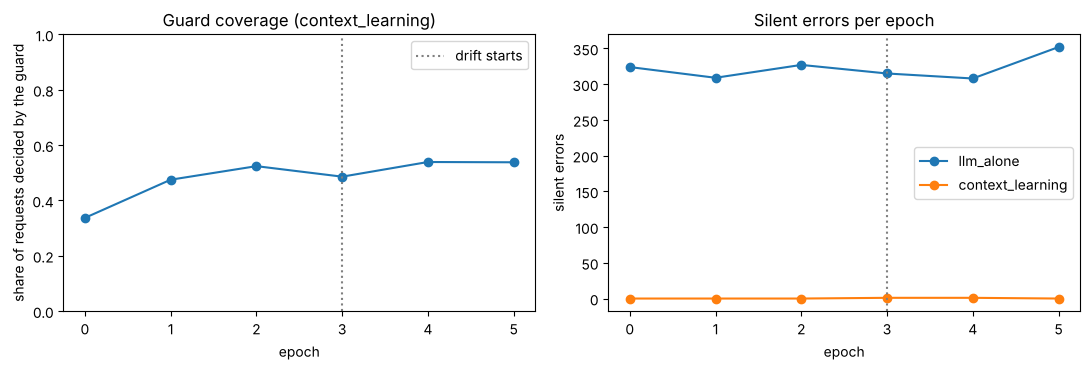

In [21]:
epochs = list(range(fcfg.epochs))
learning = res.epochs["context_learning"]
alone = res.epochs["llm_alone"]
coverage = [e.guard_confident / e.n if e.n else 0.0 for e in learning]

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

if plt is None:
    print("epoch  guard_coverage  silent(context_learning)  silent(llm_alone)")
    for i in epochs:
        print(f"{i:5}  {coverage[i]:14.2f}  {learning[i].silent_errors:24}  {alone[i].silent_errors:17}")
else:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
    ax1.plot(epochs, coverage, marker="o")
    ax1.axvline(fcfg.drift_epoch, linestyle=":", color="gray", label="drift starts")
    ax1.set_title("Guard coverage (context_learning)")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("share of requests decided by the guard")
    ax1.set_ylim(0, 1)
    ax1.legend()
    ax2.plot(epochs, [e.silent_errors for e in alone], marker="o", label="llm_alone")
    ax2.plot(epochs, [e.silent_errors for e in learning], marker="o", label="context_learning")
    ax2.axvline(fcfg.drift_epoch, linestyle=":", color="gray")
    ax2.set_title("Silent errors per epoch")
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("silent errors")
    ax2.legend()
    fig.tight_layout()
    plt.show()

## 9. Benchmark and reliability

The benchmark has ten requests with known answers.
Each arm either acts on a tax year or asks.
A silent error is acting on the wrong year, or inventing one.
This run is simulated, except the `code` arm, which is plain regex.

In [22]:
from tcxp.bench import run_bench

rows = run_bench()  # mode="simulated"
table = [{"arm": r.arm, "correct": r.correct, "silent_errors": r.silent_errors, "extra_asks": r.extra_asks,
          "errors": r.errors, "ms": round(r.ms), "tokens": r.tokens, "cost_usd": round(r.cost, 6),
          "simulated": r.simulated} for r in rows]
try:
    import pandas as pd
    display(pd.DataFrame(table).set_index("arm"))
except ImportError:
    for t in table:
        print(t)

,correct,silent_errors,extra_asks,errors,ms,tokens,cost_usd,simulated
arm,,,,,,,,
code,9,0,1,0,0,0,0.000000,False
llm_alone,8,2,0,0,8939,1778,0.002338,True
llm_with_context,10,0,0,0,4382,1215,0.001495,True
jev_alone,7,3,0,0,1177,3138,0.000132,True
jev_with_context,10,0,0,0,642,1895,0.000080,True
ladder,10,0,0,0,1678,2139,0.000380,True


How many verified examples does a decision need before it is safe to automate?

Here: a 6-step chain, an error costs $50,000, you can tolerate $100 of expected loss per decision,
40 requests a week, and people answer 90% of them.

In [23]:
from tcxp.reliability import budget

b = budget(steps=6, cost=50000, tolerated=100, volume=40, answered_pct=90)
print(f"end-to-end error allowed: {b.e2e:.4%}")
print(f"per-step error allowed:   {b.per_step:.4%}")
print(f"test cases needed:        {b.cases:,}")
print(f"weeks to collect them:    {b.weeks:,.1f}")
print(f"recommendation:           {b.recommendation}")

end-to-end error allowed: 0.2000%
per-step error allowed:   0.0334%
test cases needed:        8,979
weeks to collect them:    249.4
recommendation:           Keep a person on it, or split it


## 10. Real models (optional)

The same benchmark can call Jev and Claude.
Set `JEV_API_KEY` and `ANTHROPIC_API_KEY` first.
In Colab, store them as secrets and read them with `userdata`.
Without both keys, the cell below prints a message and does nothing.

In [24]:
import os

def _secret(name):
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata  # Colab only
        return userdata.get(name)
    except Exception:
        return None

# Or set them directly (don't commit real keys):
# os.environ["JEV_API_KEY"] = "..."
# os.environ["ANTHROPIC_API_KEY"] = "..."

jev_key, claude_key = _secret("JEV_API_KEY"), _secret("ANTHROPIC_API_KEY")
if not (jev_key and claude_key):
    print("Skipping real models: set JEV_API_KEY and ANTHROPIC_API_KEY to run this cell.")
else:
    real = run_bench("real", jev_key=jev_key, claude_key=claude_key)
    for r in real:
        print(f"{r.arm:18} correct={r.correct} silent={r.silent_errors} extra_asks={r.extra_asks} "
              f"errors={r.errors} cost=${r.cost:.4f}")

Skipping real models: set JEV_API_KEY and ANTHROPIC_API_KEY to run this cell.
